             Datetime  Temp
0 2022-01-01 00:00:00   7.5
1 2022-01-01 01:00:00   6.9
2 2022-01-01 02:00:00   6.7
3 2022-01-01 03:00:00   6.5
4 2022-01-01 04:00:00   6.5
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26304 entries, 0 to 26303
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   Datetime  26304 non-null  datetime64[ns]
 1   Temp      26304 non-null  float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 411.1 KB
None
Index(['Datetime', 'Temp'], dtype='object')
Datetime    0
Temp        0
dtype: int64
X_train: (18382, 30, 1) y_train: (18382, 1)
X_test : (7862, 30, 1) y_test : (7862, 1)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,009 (74.25 KB)

 Trainable params: 19,009 (74.25 KB)

... (5 outputs left out)

 Total params: 37,953 (148.25 KB)

 Trainable params: 37,953 (148.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
575/575 ━━━━━━━━━━━━━━━━━━━━ 18s 26ms/step - loss: 0.0038 - mae: 0.0371 - val_loss: 7.2628e-04 - val_mae: 0.0201 - learning_rate: 0.0010
Epoch 2/10
575/575 ━━━━━━━━━━━━━━━━━━━━ 14s 24ms/step - loss: 6.9318e-04 - mae: 0.0197 - val_loss: 5.5325e-04 - val_mae: 0.0174 - learning_rate: 0.0010
Epoch 3/10
575/575 ━━━━━━━━━━━━━━━━━━━━ 20s 24ms/step - loss: 5.7847e-04 - mae: 0.0177 - val_loss: 4.8614e-04 - val_mae: 0.0162 - learning_rate: 0.0010
Epoch 4/10
575/575 ━━━━━━━━━━━━━━━━━━━━ 21s 24ms/step - loss: 5.0503e-04 - mae: 0.0162 - val_loss: 3.9861e-04 - val_mae: 0.0144 - learning_rate: 0.0010
Epoch 5/10
575/575 ━━━━━━━━━━━━━━━━━━━━ 14s 24ms/step - loss: 4.5076e-04 - mae: 0.0151 - val_loss: 3.2332e-04 - val_mae: 0.0129 - learning_rate: 0.0010
Epoch 6/10
575/575 ━━━━━━━━━━━━━━━━━━━━ 14s 24ms/step - loss: 4.1976e-04 - mae: 0.0143 - val_loss: 3.1110e-04 - val_mae: 0.0127 - learning_rate: 0.0010
Epoch 7/10
575/575 ━━━━━━━━━━━━━━━━━━━━ 20s 24ms/step - loss: 4.0261e-04 - mae: 0.0138 - val

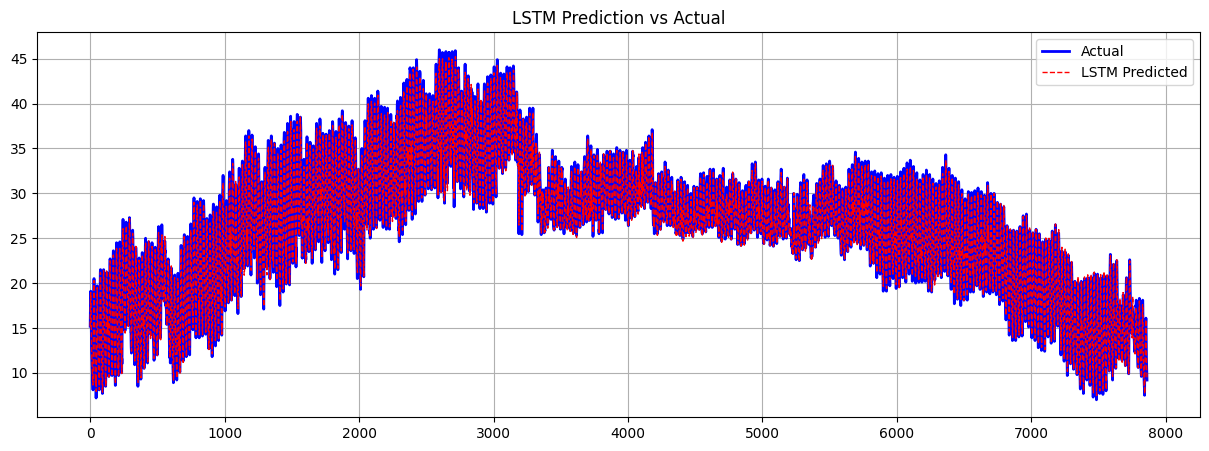

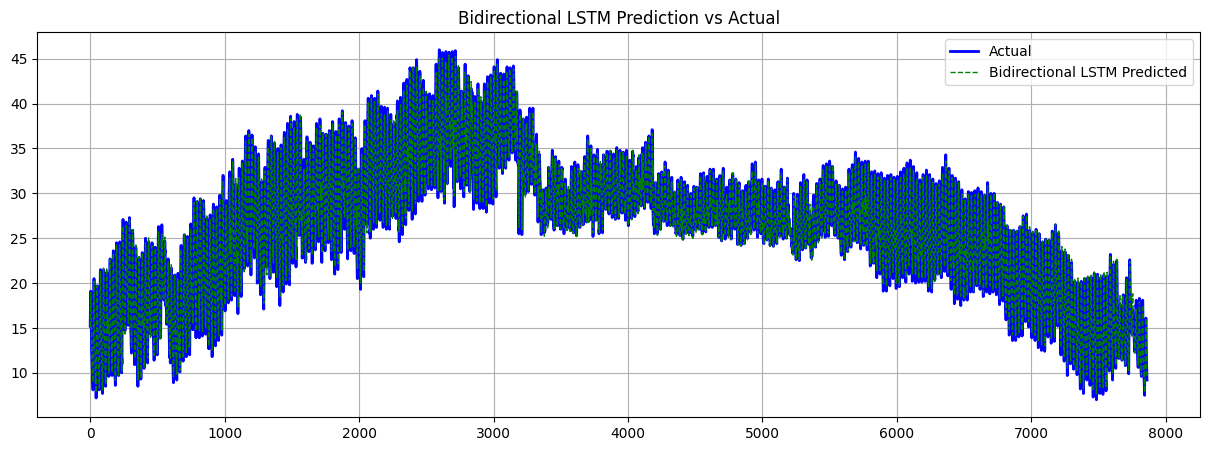

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Bidirectional, Dense
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

tf.random.set_seed(42)
np.random.seed(42)


import requests
url = ("https://archive-api.open-meteo.com/v1/archive?latitude=28.61&longitude=77.21"
       "&start_date=2022-01-01&end_date=2024-12-31&hourly=temperature_2m&timezone=auto")
h = requests.get(url, timeout=60).json()["hourly"]
df = pd.DataFrame({"Datetime": pd.to_datetime(h["time"]), "Temp": h["temperature_2m"]})
df = df.sort_values("Datetime").reset_index(drop=True)
values = df[["Temp"]].dropna().values

print(df.head())
print(df.info())
print(df.columns)
print(df.isnull().sum())

df["Datetime"] = pd.to_datetime(df["Datetime"])
df = df.sort_values("Datetime").reset_index(drop=True)

values = df[["Temp"]].dropna().values

train_size = int(len(values) * 0.7)
train_raw = values[:train_size]
test_raw = values[train_size:]

scaler = MinMaxScaler()
train_scaled = scaler.fit_transform(train_raw)
test_scaled = scaler.transform(test_raw)



def create_sequences(data, lookback=30):
    X, y = [], []
    for i in range(len(data) - lookback):
        X.append(data[i : i + lookback])
        y.append(data[i + lookback])
    return np.array(X, dtype=np.float32), np.array(y, dtype=np.float32)


lookback = 30
X_train, y_train = create_sequences(train_scaled, lookback)
X_test, y_test = create_sequences(test_scaled, lookback)

print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_test :", X_test.shape, "y_test :", y_test.shape)


def make_callbacks():
    return [
        EarlyStopping(
            monitor="val_loss",
            patience=5,
            restore_best_weights=True,
        ),
        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.6,
            patience=3.2,
            verbose=1,
        ),
    ]


#  Unidirectional
lstm_model = Sequential([
    LSTM(64, input_shape=(lookback, 1)),
    Dense(32, activation="relu"),
    Dense(1),
])

lstm_model.compile(optimizer="adam", loss="mse", metrics=["mae"])
lstm_model.summary()

history_lstm = lstm_model.fit(
    X_train,
    y_train,
    validation_data=(X_test, y_test),
    epochs=15,
    batch_size=32,
    callbacks=make_callbacks(),
    verbose=1,
)

loss_lstm, mae_lstm = lstm_model.evaluate(X_test, y_test, verbose=0)
print(f"LSTM -> Loss (MSE): {loss_lstm:.6f}, MAE: {mae_lstm:.6f}")

# Bidirectional
bilstm_model = Sequential([
    Bidirectional(LSTM(64), input_shape=(lookback, 1)),
    Dense(32, activation="relu"),
    Dense(1),
])

bilstm_model.compile(optimizer="adam", loss="mse", metrics=["mae"])
bilstm_model.summary()

history_bilstm = bilstm_model.fit(
    X_train,
    y_train,
    validation_data=(X_test, y_test),
    epochs=10,
    batch_size=32,
    callbacks=make_callbacks(),
    verbose=1,
)

loss_bilstm, mae_bilstm = bilstm_model.evaluate(X_test, y_test, verbose=0)
print(f"BiLSTM -> Loss (MSE): {loss_bilstm:.6f}, MAE: {mae_bilstm:.6f}")

#  Comparison table
comparison = pd.DataFrame({
    "Model": ["LSTM", "Bidirectional LSTM"],
    "Loss": [loss_lstm, loss_bilstm],
    "MAE": [mae_lstm, mae_bilstm],
})
print(comparison)


actual = scaler.inverse_transform(y_test)
pred_lstm = scaler.inverse_transform(lstm_model.predict(X_test, verbose=0))
pred_bilstm = scaler.inverse_transform(bilstm_model.predict(X_test, verbose=0))

plt.figure(figsize=(15, 5))
plt.plot(actual, label="Actual", color="blue", linewidth=2)
plt.plot(pred_lstm, label="LSTM Predicted", color="red", linestyle="--", linewidth=1)
plt.legend()
plt.title("LSTM Prediction vs Actual")
plt.grid(True)
plt.show()

plt.figure(figsize=(15, 5))
plt.plot(actual, label="Actual", color="blue", linewidth=2)
plt.plot(pred_bilstm, label="Bidirectional LSTM Predicted", color="green", linestyle="--", linewidth=1)
plt.legend()
plt.title("Bidirectional LSTM Prediction vs Actual")
plt.grid(True)
plt.show()